# 04 — Phân tích Lỗi, So sánh Mô hình & Trực quan hóa (Error Analysis)

**Người phụ trách:** Đạt

Notebook này đọc các file kết quả `.json` trong `outputs/metrics/` và file dự đoán `.jsonl` trong `outputs/predictions/` theo đúng **Hợp đồng giao diện** (`docs/interface_contract.md`).

- **Chế độ tự động:** Nếu đã có file dự đoán thật của Tín (`bilstm_crf_full_test.jsonl`, `bilstm_softmax_test.jsonl`) và Đức Anh (`phobert_full_test.jsonl`) trong `outputs/predictions/`, notebook sẽ phân tích kết quả thật.
- **Chế độ chạy thử (Dummy Mode):** Khi mô hình của Tín và Đức Anh chưa huấn luyện xong, notebook tự động sinh dự đoán giả lập có kiểm soát (`DUMMY_*`) trên tập `test_word.json`, lưu vào `outputs/predictions/dummy/` và `outputs/metrics/dummy/` để kiểm thử toàn bộ pipeline biểu đồ, bảng lỗi và ví dụ mẫu. Khi có kết quả thật, chỉ cần chạy lại toàn bộ notebook.

In [1]:
# Cell thiết lập: chạy được cả trên Kaggle, Colab và máy cá nhân.
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/TTins1702/NER-PhoNER_COVID19-UET.git"
REPO_NAME = "NER-PhoNER_COVID19-UET"
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ

if IN_COLAB or IN_KAGGLE:
    base = Path("/kaggle/working") if IN_KAGGLE else Path("/content")
    ROOT = base / REPO_NAME
    if not (ROOT / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
    else:
        subprocess.run(["git", "-C", str(ROOT), "pull"], check=True)
else:
    ROOT = Path.cwd()
    while not (ROOT / "src").is_dir() and ROOT.parent != ROOT:
        ROOT = ROOT.parent

os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Thư mục làm việc:", ROOT)


Thư mục làm việc: C:\Users\ThinkPad\Downloads\NER-PhoNER_COVID19-UET


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.download import download_phoner_covid19, load_split
from src.data.labels import ENTITY_TYPES, SHORT_NAMES, display_name
from src.data.vocab import WordVocab
from src.evaluation.predictions import load_predictions, save_predictions
from src.evaluation.metrics import compute_metrics, evaluate_and_save, load_metrics_json
from src.evaluation.error_analysis import (
    ERROR_NAMES_VI,
    ERROR_TYPES,
    analyze_errors,
    compare_models,
    entity_confusion_matrix,
    error_samples_table,
    format_tagged_sentence,
    pick_sentence_examples,
    recall_by_entity_length,
    recall_by_oov,
)
from src.evaluation.dummy_predictions import make_profile_predictions
from src.evaluation.plots import (
    configure_acl_style,
    plot_bio_violations,
    plot_confusion_matrix,
    plot_error_breakdown,
    plot_per_entity_f1,
    plot_recall_by_length,
    save_figure,
)

configure_acl_style()
DATA_DIR = Path("data")
PRED_DIR = Path("outputs/predictions")
METRICS_DIR = Path("outputs/metrics")
FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

download_phoner_covid19(DATA_DIR)
train_samples = load_split("train", "word", DATA_DIR)
test_samples = load_split("test", "word", DATA_DIR)
train_vocab = WordVocab.build([s["words"] for s in train_samples], min_freq=1)
print(f"Đã nạp train={len(train_samples)} câu (vocab={len(train_vocab)}), test={len(test_samples)} câu.")

[download] 'data' đã có đủ dữ liệu. Bỏ qua (dùng --force để tải lại).
Đã nạp train=5027 câu (vocab=5169), test=3000 câu.


## 1. Nạp dự đoán thật hoặc khởi tạo dự đoán giả để chạy thử

In [3]:
REAL_FILES = {
    "BiLSTM-Softmax": ("bilstm_softmax", PRED_DIR / "bilstm_softmax_test.jsonl", METRICS_DIR / "bilstm_softmax_test.json"),
    "BiLSTM-CRF": ("bilstm_crf_full", PRED_DIR / "bilstm_crf_full_test.jsonl", METRICS_DIR / "bilstm_crf_full_test.json"),
    "PhoBERT": ("phobert_full", PRED_DIR / "phobert_full_test.jsonl", METRICS_DIR / "phobert_full_test.json"),
}

DUMMY_MODE = not all(p.is_file() for _, p, _ in REAL_FILES.values())
predictions = {}
metrics_results = {}

if not DUMMY_MODE:
    print(">>> ĐANG CHẠY TRÊN DỰ ĐOÁN THẬT <<<")
    for label, (exp_name, pred_path, metric_path) in REAL_FILES.items():
        words_list, y_true, y_pred = load_predictions(pred_path)
        predictions[label] = (words_list, y_true, y_pred)
        if metric_path.is_file():
            metrics_results[label] = load_metrics_json(metric_path)
        else:
            metrics_results[label] = evaluate_and_save(
                y_true, y_pred, experiment_name=exp_name,
                model="phobert" if "phobert" in exp_name else "bilstm_crf",
                split="test", level="word", group="main", description=label,
                out_dir=METRICS_DIR, verbose=False,
            )
else:
    print(">>> CHƯA CÓ ĐỦ FILE DỰ ĐOÁN THẬT — CHẠY THỬ BẰNG DỮ LIỆU GIẢ (DUMMY_MODE = True) <<<")
    dummy_pred_dir = PRED_DIR / "dummy"
    dummy_metric_dir = METRICS_DIR / "dummy"
    words_list = [s["words"] for s in test_samples]
    y_true = [s["tags"] for s in test_samples]
    profile_map = [
        ("BiLSTM-Softmax (DUMMY)", "DUMMY_bilstm_softmax", "bilstm_crf", "ablation_bilstm", False),
        ("BiLSTM-CRF (DUMMY)", "DUMMY_bilstm_crf", "bilstm_crf", "main", True),
        ("PhoBERT (DUMMY)", "DUMMY_phobert", "phobert", "main", True),
    ]
    for label, profile, model_key, group, is_ref in profile_map:
        y_pred = make_profile_predictions(y_true, profile)
        pred_path = save_predictions(dummy_pred_dir / f"{profile}_test.jsonl", words_list, y_true, y_pred)
        res = evaluate_and_save(
            y_true, y_pred, experiment_name=profile, model=model_key,
            split="test", level="word", group=group, description=label,
            is_ablation_reference=is_ref, out_dir=dummy_metric_dir, verbose=False,
        )
        predictions[label] = (words_list, y_true, y_pred)
        metrics_results[label] = res
    print("Đã sinh file dự đoán và metrics giả tại:", dummy_pred_dir, "và", dummy_metric_dir)

>>> CHƯA CÓ ĐỦ FILE DỰ ĐOÁN THẬT — CHẠY THỬ BẰNG DỮ LIỆU GIẢ (DUMMY_MODE = True) <<<


Đã sinh file dự đoán và metrics giả tại: outputs\predictions\dummy và outputs\metrics\dummy


## 2. Bảng tổng hợp P / R / Micro-F1 / Macro-F1 và thống kê vi phạm BIO

In [4]:
summary_rows = []
for label, res in metrics_results.items():
    mic = res["overall"]["micro"]
    mac = res["overall"]["macro"]
    viol = res["bio_violations"]["pred"]
    _, yt, yp = predictions[label]
    repaired = compute_metrics(yt, yp, repair=True)
    summary_rows.append({
        "Mô hình": label,
        "Micro-P (%)": round(100 * mic["precision"], 2),
        "Micro-R (%)": round(100 * mic["recall"], 2),
        "Micro-F1 (%)": round(100 * mic["f1"], 2),
        "Macro-F1 (%)": round(100 * mac["f1"], 2),
        "Vi phạm BIO (nhãn)": viol["total"],
        "Vi phạm BIO (câu)": viol["sentences_with_violation"],
        "Micro-F1 sau sửa BIO (%)": round(100 * repaired["overall"]["micro"]["f1"], 2),
    })
summary_df = pd.DataFrame(summary_rows)
summary_df

,Mô hình,Micro-P (%),Micro-R (%),Micro-F1 (%),Macro-F1 (%),Vi phạm BIO (nhãn),Vi phạm BIO (câu),Micro-F1 sau sửa BIO (%)
0,BiLSTM-Softmax (DUMMY),79.09,71.31,75.00,68.92,555,489,78.03
1,BiLSTM-CRF (DUMMY),83.51,79.99,81.71,76.28,0,0,81.71
2,PhoBERT (DUMMY),91.62,89.03,90.31,86.78,137,134,90.95


## 3. Biểu đồ F1 theo từng loại thực thể (10 loại, đọc tốt ở thang xám)

,Thực thể,Viết tắt,Support,BiLSTM-Softmax (DUMMY) F1 (%),BiLSTM-CRF (DUMMY) F1 (%),PhoBERT (DUMMY) F1 (%)
0,AGE,AGE,582,68.65,78.77,87.14
1,DATE,DATE,1654,77.39,83.09,89.88
2,GENDER,GEN,462,66.74,76.37,86.99
3,OCCUPATION,JOB,173,55.71,63.11,78.44
4,LOCATION,LOC,4441,79.41,85.07,92.33
5,PERSON_NAME,NAME,318,61.19,72.94,84.55
6,ORGANIZATION,ORG,771,71.62,80.39,89.46
7,PATIENT_ID,PID,2005,76.76,83.22,92.01
8,SYMPTOM_AND_DISEASE,SYM,1136,73.95,80.36,90.26
9,TRANSPORTATION,TRANS,193,57.82,59.45,76.78


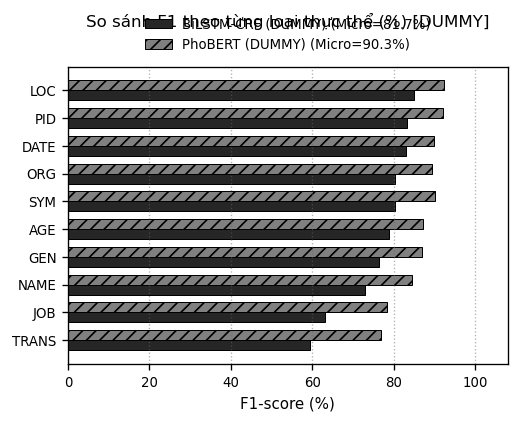

In [5]:
per_ent_rows = []
for t in ENTITY_TYPES:
    row = {"Thực thể": display_name(t), "Viết tắt": SHORT_NAMES[t],
           "Support": next(iter(metrics_results.values()))["per_entity"][t]["support"]}
    for label, res in metrics_results.items():
        row[f"{label} F1 (%)"] = round(100 * res["per_entity"][t]["f1"], 2)
    per_ent_rows.append(row)
per_ent_df = pd.DataFrame(per_ent_rows)
display(per_ent_df)

# So sánh 2 mô hình chính: BiLSTM-CRF và PhoBERT
main_keys = [k for k in metrics_results if "Softmax" not in k]
fig = plot_per_entity_f1(
    [metrics_results[k] for k in main_keys],
    labels=main_keys,
    title="So sánh F1 theo từng loại thực thể (%)" + (" [DUMMY]" if DUMMY_MODE else ""),
)
save_figure(fig, "eval_per_entity_f1", FIG_DIR)
plt.show()

## 4. Ma trận nhầm lẫn mức thực thể (Entity-level Confusion Matrix)

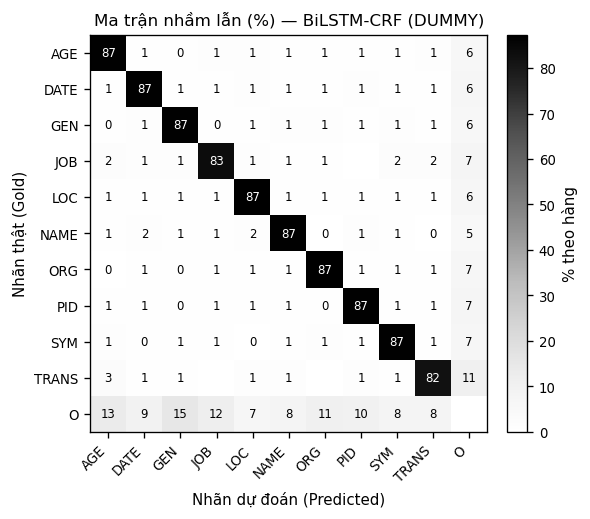

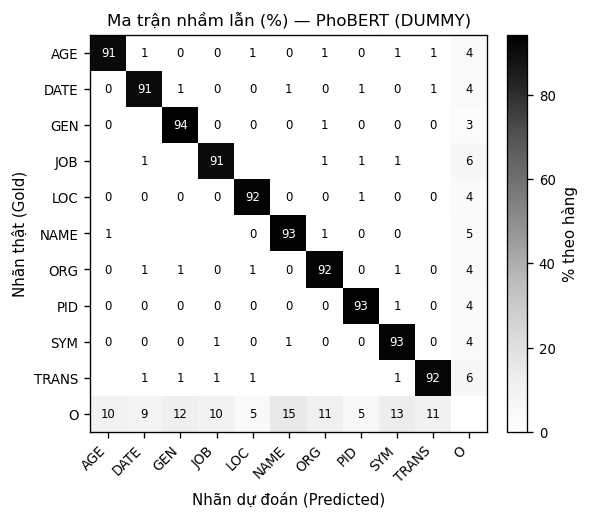

In [6]:
for k, slug in zip(main_keys, ("bilstm", "phobert")):
    words_list, yt, yp = predictions[k]
    mat, cm_labels = entity_confusion_matrix(yt, yp)
    fig = plot_confusion_matrix(
        mat, cm_labels, normalize_rows=True,
        title=f"Ma trận nhầm lẫn (%) — {k}",
    )
    save_figure(fig, f"eval_confusion_matrix_{slug}", FIG_DIR)
    plt.show()

## 5. Phân loại 4 nhóm lỗi (Boundary, Type, False Positive, False Negative) và Vi phạm BIO

,Mô hình,Thực thể đúng (TP),Lỗi ranh giới (Boundary),Nhầm loại (Type),Báo nhầm (FP),Bỏ sót (FN),Tổng lỗi,Số câu có lỗi
0,BiLSTM-Softmax (DUMMY),8368,883 (23.7%),969 (26.0%),360 (9.7%),1508 (40.5%),3720,2001
1,BiLSTM-CRF (DUMMY),9387,802 (30.6%),782 (29.9%),270 (10.3%),764 (29.2%),2618,1668
2,PhoBERT (DUMMY),10448,381 (26.5%),423 (29.4%),152 (10.6%),482 (33.5%),1438,1110


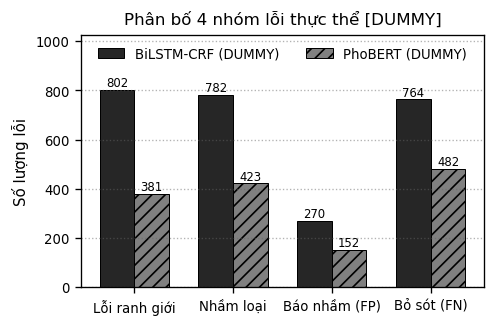

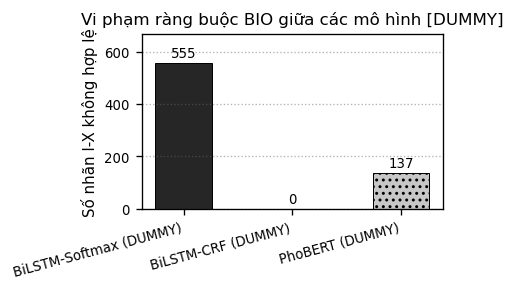

In [7]:
error_reports = {}
breakdown_rows = []
for label, (words_list, yt, yp) in predictions.items():
    rep = analyze_errors(words_list, yt, yp)
    error_reports[label] = rep
    c = rep.counts
    total_err = sum(c[et] for et in ERROR_TYPES)
    breakdown_rows.append({
        "Mô hình": label,
        "Thực thể đúng (TP)": c["correct"],
        "Lỗi ranh giới (Boundary)": f"{c['boundary']} ({100*c['boundary']/max(1,total_err):.1f}%)",
        "Nhầm loại (Type)": f"{c['type']} ({100*c['type']/max(1,total_err):.1f}%)",
        "Báo nhầm (FP)": f"{c['false_positive']} ({100*c['false_positive']/max(1,total_err):.1f}%)",
        "Bỏ sót (FN)": f"{c['false_negative']} ({100*c['false_negative']/max(1,total_err):.1f}%)",
        "Tổng lỗi": total_err,
        "Số câu có lỗi": rep.num_sentences_with_error,
    })
display(pd.DataFrame(breakdown_rows))

fig_err = plot_error_breakdown(
    {k: error_reports[k].counts for k in main_keys},
    title="Phân bố 4 nhóm lỗi thực thể" + (" [DUMMY]" if DUMMY_MODE else ""),
)
save_figure(fig_err, "eval_error_breakdown", FIG_DIR)
plt.show()

fig_bio = plot_bio_violations(
    list(metrics_results.values()),
    labels=list(metrics_results.keys()),
    title="Vi phạm ràng buộc BIO giữa các mô hình" + (" [DUMMY]" if DUMMY_MODE else ""),
)
save_figure(fig_bio, "eval_bio_violations", FIG_DIR)
plt.show()

## 6. Phân tích Recall theo độ dài thực thể và theo từ ngoài từ điển (OOV)

,Mô hình,Recall thực thể đã biết (%),Support (đã biết),Recall thực thể có từ OOV (%),Support (có OOV)
0,BiLSTM-CRF (DUMMY),80.10,10271,79.23,1464
1,PhoBERT (DUMMY),88.99,10271,89.34,1464


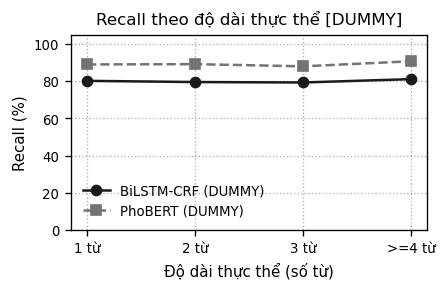

In [8]:
len_recalls = {}
oov_rows = []
for k in main_keys:
    words_list, yt, yp = predictions[k]
    len_recalls[k] = recall_by_entity_length(yt, yp)
    oov_res = recall_by_oov(words_list, yt, yp, train_vocab)
    oov_rows.append({
        "Mô hình": k,
        "Recall thực thể đã biết (%)": round(100 * oov_res["all_known"]["recall"], 2),
        "Support (đã biết)": oov_res["all_known"]["support"],
        "Recall thực thể có từ OOV (%)": round(100 * oov_res["has_oov"]["recall"], 2),
        "Support (có OOV)": oov_res["has_oov"]["support"],
    })
display(pd.DataFrame(oov_rows))

fig_len = plot_recall_by_length(
    len_recalls,
    title="Recall theo độ dài thực thể" + (" [DUMMY]" if DUMMY_MODE else ""),
)
save_figure(fig_len, "eval_recall_by_length", FIG_DIR)
plt.show()

## 7. Đối chiếu trực tiếp BiLSTM-CRF và PhoBERT & Ví dụ câu dự đoán đúng/sai điển hình

In [9]:
k_bilstm, k_phobert = main_keys[0], main_keys[1]
words_list, yt, yp_bilstm = predictions[k_bilstm]
_, _, yp_phobert = predictions[k_phobert]

cmp_res = compare_models(yt, yp_bilstm, yp_phobert)
print("Thống kê mức câu (A = BiLSTM-CRF, B = PhoBERT):", cmp_res["sentence_counts"])
print("Thống kê mức thực thể gold (A = BiLSTM-CRF, B = PhoBERT):", cmp_res["entity_counts"])

# Bảng theo từng loại thực thể: bao nhiêu thực thể chỉ PhoBERT đúng (only_b)
cmp_type_df = pd.DataFrame(cmp_res["entity_counts_by_type"]).T
cmp_type_df.columns = ["Cả hai đúng", "Chỉ BiLSTM-CRF đúng", "Chỉ PhoBERT đúng", "Cả hai sai"]
display(cmp_type_df)

Thống kê mức câu (A = BiLSTM-CRF, B = PhoBERT): {'both_correct': 965, 'only_a': 367, 'only_b': 925, 'both_wrong': 743}
Thống kê mức thực thể gold (A = BiLSTM-CRF, B = PhoBERT): {'both': 8367, 'only_a': 1020, 'only_b': 2081, 'neither': 267}


,Cả hai đúng,Chỉ BiLSTM-CRF đúng,Chỉ PhoBERT đúng,Cả hai sai
AGE,405,70,100,7
DATE,1156,168,287,43
GENDER,338,37,80,7
JOB,121,15,30,7
LOCATION,3196,374,764,107
NAME,229,23,61,5
ORGANIZATION,560,61,132,18
PATIENT_ID,1443,157,364,41
SYMPTOM_AND_DISEASE,799,95,216,26
TRANSPORTATION,120,20,47,6


In [10]:
# Ví dụ câu PhoBERT đúng hoàn toàn nhưng BiLSTM-CRF sai
only_phobert_ids = cmp_res["sentence_ids"]["only_b"][:5]
print("=== Ví dụ câu PhoBERT đúng nhưng BiLSTM-CRF sai ===")
for sid in only_phobert_ids:
    if len(words_list[sid]) <= 35:
        print(f"[Câu #{sid}]")
        print("  GOLD      :", format_tagged_sentence(words_list[sid], yt[sid]))
        print("  BiLSTM-CRF:", format_tagged_sentence(words_list[sid], yp_bilstm[sid]))
        print("  PhoBERT   :", format_tagged_sentence(words_list[sid], yp_phobert[sid]))

# Bảng câu sai mẫu theo 4 nhóm lỗi của BiLSTM-CRF
samples_df = error_samples_table(error_reports[k_bilstm], words_list, yt, yp_bilstm, n_per_type=3)
out_sample_csv = (METRICS_DIR / "dummy" if DUMMY_MODE else METRICS_DIR) / "error_samples_bilstm.csv"
samples_df.to_csv(out_sample_csv, index=False, encoding="utf-8-sig")
print("Đã lưu bảng câu sai mẫu tại:", out_sample_csv)
samples_df[["error_name", "sent_id", "gold_type", "pred_type", "gold_text", "pred_text"]]

=== Ví dụ câu PhoBERT đúng nhưng BiLSTM-CRF sai ===
[Câu #9]
  GOLD      : Theo đó bệnh_nhân tên [N.M.C.]NAME , là [nhân_viên ngân_hàng]JOB tại [38 Hàng Da]LOC , [phường Hàng Bông]LOC , [quận Hoàn_Kiếm]LOC .
  BiLSTM-CRF: Theo đó bệnh_nhân tên [N.M.C.]NAME , là [nhân_viên ngân_hàng]JOB tại [38 Hàng Da ,]LOC [phường Hàng Bông]LOC , [quận Hoàn_Kiếm]LOC .
  PhoBERT   : Theo đó bệnh_nhân tên [N.M.C.]NAME , là [nhân_viên ngân_hàng]JOB tại [38 Hàng Da]LOC , [phường Hàng Bông]LOC , [quận Hoàn_Kiếm]LOC .
[Câu #13]
  GOLD      : Trong thời_gian ở đây , em đi chơi [công_viên SunWorld Đà_Nẵng]LOC , [siêu_thị Lotte_Mart]LOC và ăn_ở một_số quán .
  BiLSTM-CRF: Trong thời_gian ở đây , em đi chơi [công_viên SunWorld Đà_Nẵng ,]LOC [siêu_thị Lotte_Mart]LOC và ăn_ở một_số quán .
  PhoBERT   : Trong thời_gian ở đây , em đi chơi [công_viên SunWorld Đà_Nẵng]LOC , [siêu_thị Lotte_Mart]LOC và ăn_ở một_số quán .
[Câu #16]
  GOLD      : Trước đó , khi điều_trị tại hai bệnh_viện ở [Đà_Nẵng]LOC , bệnh_nhân [viêm

,error_name,sent_id,gold_type,pred_type,gold_text,pred_text
0,Lỗi ranh giới,2626,ORGANIZATION,ORGANIZATION,Trung_tâm Kiểm_soát bệnh_tật tỉnh Ninh_Thuận,"Trung_tâm Kiểm_soát bệnh_tật tỉnh Ninh_Thuận ,"
1,Lỗi ranh giới,402,ORGANIZATION,ORGANIZATION,Bộ Y_tế,Bộ Y_tế xác_nhận
2,Lỗi ranh giới,99,PATIENT_ID,PATIENT_ID,592,"592 """
3,Nhầm loại,963,LOCATION,DATE,thị_trấn Nam_Phước,thị_trấn Nam_Phước
4,Nhầm loại,856,ORGANIZATION,DATE,Trung_tâm y_tế huyện Thuỷ_Nguyên,Trung_tâm y_tế huyện Thuỷ_Nguyên
5,Nhầm loại,761,LOCATION,SYMPTOM_AND_DISEASE,Quảng_Ninh,Quảng_Ninh
6,Báo nhầm (FP),844,,LOCATION,,trạm
7,Báo nhầm (FP),647,,PATIENT_ID,,được
8,Báo nhầm (FP),603,,NAME,,đều
9,Bỏ sót (FN),2376,LOCATION,,sân_bay Tân_Sơn_Nhất,
